<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session01_ml_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱: مقدمه‌ای بر یادگیری ماشین و جریان کار آن

### اهداف این جلسه

- آشنایی با مفهوم یادگیری ماشین و تفاوت آن با برنامه‌نویسی سنتی
- شناخت انواع اصلی یادگیری ماشین: نظارت‌شده، بدون نظارت و تقویتی
- آشنایی با واژگان پایه: نمونه، ویژگی، برچسب، مدل، آموزش و پیش‌بینی
- دیدن کل جریان کار یک پروژهٔ یادگیری ماشین روی یک مثال واقعی و کوچک
- آشنایی با رابط یکسان کتابخانهٔ scikit-learn (`fit` و `predict`)

## ۱. یادگیری ماشین چیست؟

در **برنامه‌نویسی سنتی**، ما قانون‌ها را خودمان می‌نویسیم: «اگر ایمیل شامل کلمهٔ «جایزه» بود، آن را هرزنامه در نظر بگیر». ورودی برنامه، داده و قانون است و خروجی آن، جواب.

در **یادگیری ماشین (Machine Learning)**، قانون را نمی‌نویسیم. به‌جای آن، تعداد زیادی مثال همراه با جواب درست به الگوریتم می‌دهیم و الگوریتم خودش قانون (یعنی **مدل**) را از روی داده یاد می‌گیرد. سپس از این مدل برای پیش‌بینی جواب مثال‌های جدید استفاده می‌کنیم.

تعریف معروف تام میچل (Tom Mitchell): برنامه‌ای که با کسب **تجربهٔ E** در انجام **وظیفهٔ T**، طبق **معیار عملکرد P** بهتر می‌شود، در حال یادگیری است. برای فیلتر هرزنامه: T تشخیص هرزنامه است، E ایمیل‌هایی که کاربران برچسب زده‌اند و P درصد ایمیل‌هایی که درست تشخیص داده می‌شوند.

یادگیری ماشین وقتی مفید است که:
- نوشتن قانون به‌صورت دستی سخت یا غیرممکن باشد (مثل تشخیص چهره)
- قانون‌ها مدام تغییر کنند (مثل الگوهای تقلب بانکی)
- دادهٔ زیادی در دسترس باشد و بخواهیم الگوهای پنهان آن را کشف کنیم

## ۲. انواع یادگیری ماشین

| نوع | دادهٔ آموزشی | هدف | مثال |
|---|---|---|---|
| **نظارت‌شده (Supervised)** | ویژگی‌ها + برچسب درست | پیش‌بینی برچسب دادهٔ جدید | پیش‌بینی قیمت خانه، تشخیص هرزنامه |
| **بدون نظارت (Unsupervised)** | فقط ویژگی‌ها، بدون برچسب | کشف ساختار پنهان داده | بخش‌بندی مشتریان، کاهش ابعاد |
| **تقویتی (Reinforcement)** | پاداش یا جریمه از محیط | یادگیری بهترین رفتار | بازی‌های رایانه‌ای، رباتیک |

یادگیری نظارت‌شده خودش دو دسته دارد:
- **رگرسیون (Regression):** خروجی یک عدد پیوسته است؛ مثل قیمت خانه یا دمای فردا.
- **طبقه‌بندی (Classification):** خروجی یک دسته از میان چند دستهٔ مشخص است؛ مثل «هرزنامه / عادی» یا نوع گل.

در این دوره روی یادگیری نظارت‌شده و بدون نظارت با مدل‌های کلاسیک تمرکز می‌کنیم. شبکه‌های عصبی و یادگیری عمیق موضوع ترم بعد است.

## ۳. واژگان پایه

- **مجموعه‌داده (Dataset):** جدولی از داده‌ها
- **نمونه (Sample / Instance):** هر سطر جدول؛ مثلاً یک گل یا یک مشتری
- **ویژگی (Feature):** هر ستونی که برای پیش‌بینی استفاده می‌شود؛ معمولاً ماتریس ویژگی‌ها را با $X$ نشان می‌دهیم
- **برچسب یا هدف (Label / Target):** ستونی که می‌خواهیم پیش‌بینی کنیم؛ معمولاً با $y$ نشان داده می‌شود
- **مدل (Model):** تابعی که از روی $X$ مقدار $y$ را تخمین می‌زند
- **آموزش (Training / Fitting):** فرایند یافتن بهترین پارامترهای مدل از روی داده
- **تعمیم (Generalization):** توانایی مدل در پیش‌بینی درست برای داده‌هایی که هرگز ندیده است. **هدف اصلی یادگیری ماشین همین است**، نه حفظ کردن دادهٔ آموزشی.

## ۴. جریان کار یک پروژهٔ یادگیری ماشین

تقریباً همهٔ پروژه‌های یادگیری ماشین این مراحل را طی می‌کنند:

1. **تعریف مسئله:** چه چیزی را می‌خواهیم پیش‌بینی کنیم و موفقیت را چطور می‌سنجیم؟
2. **جمع‌آوری و بارگذاری داده**
3. **تحلیل اکتشافی داده (EDA):** شناخت داده، توزیع‌ها، مقادیر گمشده و روابط
4. **پیش‌پردازش:** پاک‌سازی، تبدیل ویژگی‌های متنی به عدد، مقیاس‌بندی
5. **تقسیم داده به آموزش و آزمون**
6. **آموزش مدل**
7. **ارزیابی مدل روی دادهٔ آزمون**
8. **بهبود:** امتحان مدل‌ها و تنظیمات دیگر
9. **استقرار (Deployment):** استفاده از مدل در دنیای واقعی

در ادامهٔ همین جلسه، این مراحل را روی یک مجموعه‌دادهٔ کوچک و معروف اجرا می‌کنیم. در جلسه‌های بعد، هر مرحله را عمیق‌تر یاد می‌گیریم.

## ۵. ابزارها

در ترم علم داده با NumPy، pandas، Matplotlib و Seaborn کار کردیم. در این ترم ابزار اصلی ما **scikit-learn** است: کتابخانهٔ استاندارد یادگیری ماشین کلاسیک در پایتون. در جلسه‌های بعد با **statsmodels**، **XGBoost**، **LightGBM**، **imbalanced-learn** و **mlxtend** هم آشنا می‌شویم.

ساده‌ترین راه اجرای نوت‌بوک‌ها **Google Colab** است که همهٔ این کتابخانه‌ها را از قبل نصب دارد.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid")

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.3
pandas: 3.0.5
scikit-learn: 1.9.1


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. مثال عملی: طبقه‌بندی گل زنبق (Iris)

### ۶.۱ تعریف مسئله

مجموعه‌دادهٔ **Iris** شامل اندازه‌های ۱۵۰ گل زنبق از سه گونه است: *setosa*، *versicolor* و *virginica*. برای هر گل چهار ویژگی اندازه‌گیری شده است: طول و عرض کاسبرگ (sepal) و طول و عرض گلبرگ (petal).

**مسئله:** با داشتن این چهار اندازه، گونهٔ گل را پیش‌بینی کنیم. این یک مسئلهٔ **طبقه‌بندی** با سه کلاس است. معیار موفقیت را **دقت (accuracy)** در نظر می‌گیریم: درصد گل‌هایی که گونهٔ آن‌ها درست پیش‌بینی می‌شود.

### ۶.۲ بارگذاری داده

این مجموعه‌داده همراه scikit-learn ارائه می‌شود و نیازی به دانلود ندارد.

</div>

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ۶.۳ تحلیل اکتشافی داده

اولین قدم همیشه شناختن داده است: چند نمونه داریم؟ نوع ستون‌ها چیست؟ مقدار گمشده داریم؟ کلاس‌ها متوازن‌اند؟

</div>

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (150, 6)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


In [5]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

داده ۱۵۰ نمونه و ۴ ویژگی عددی دارد، هیچ مقدار گمشده‌ای ندارد و از هر گونه دقیقاً ۵۰ نمونه موجود است؛ یعنی کلاس‌ها **متوازن** هستند.

حالا با یک نمودار ببینیم ویژگی‌ها چقدر می‌توانند گونه‌ها را از هم جدا کنند:

</div>

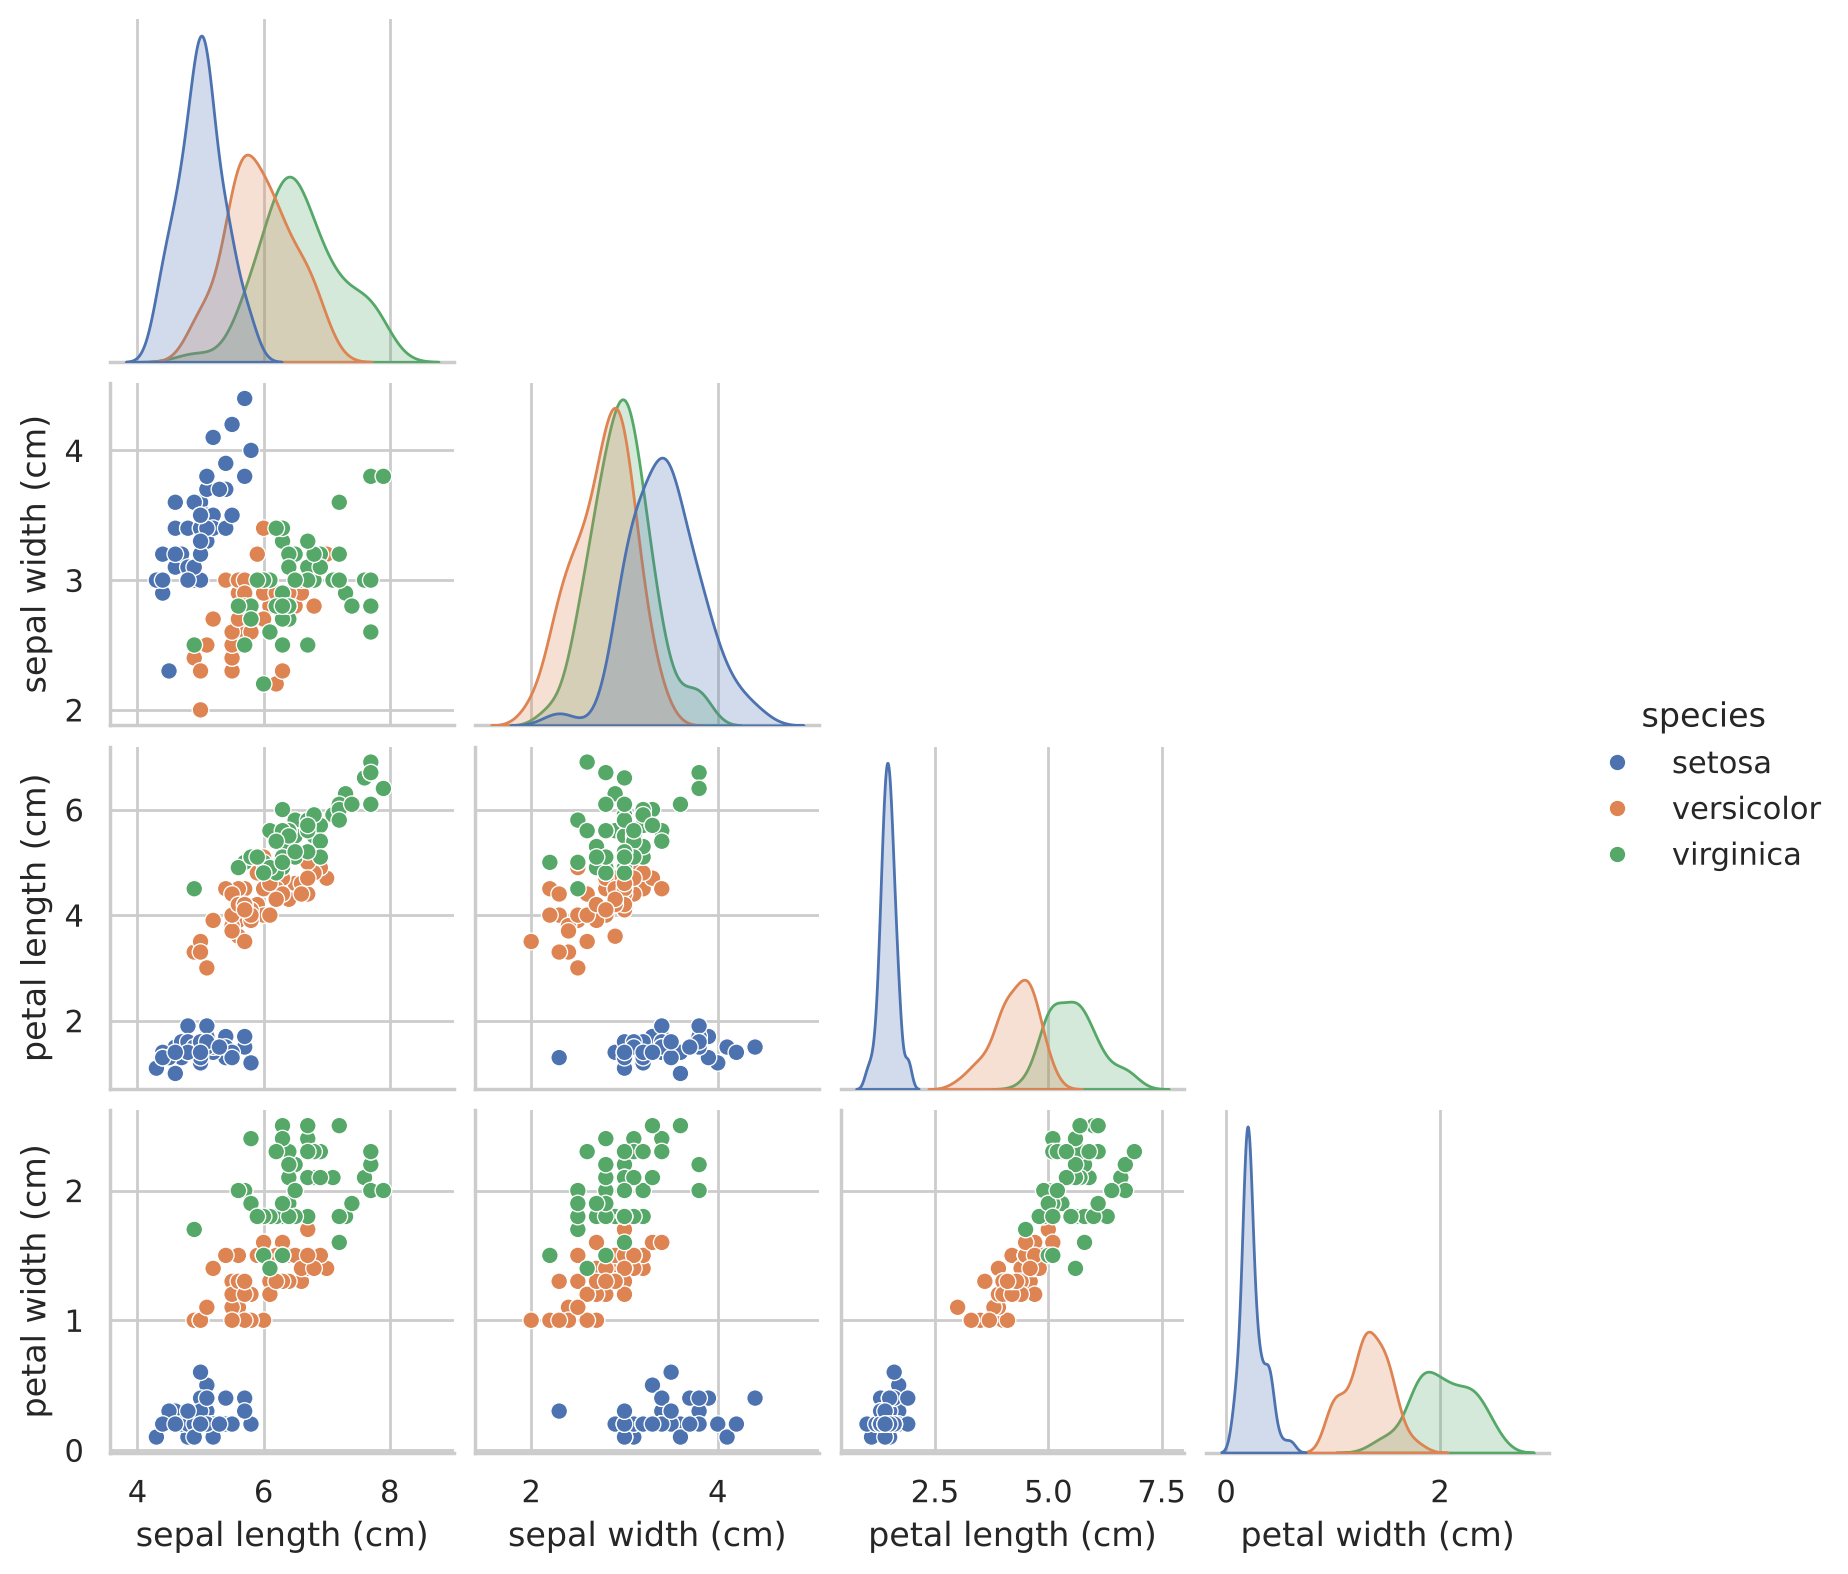

In [6]:
sns.pairplot(df.drop(columns="target"), hue="species", height=2.0, corner=True)
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

از نمودار پیداست که گونهٔ *setosa* با ویژگی‌های گلبرگ (petal) کاملاً از بقیه جداست. دو گونهٔ دیگر کمی هم‌پوشانی دارند. پس انتظار داریم یک مدل ساده هم دقت بالایی داشته باشد، ولی احتمالاً بین *versicolor* و *virginica* چند اشتباه رخ دهد.

### ۶.۴ آماده‌سازی داده و تقسیم به آموزش و آزمون

ماتریس ویژگی‌ها $X$ و بردار برچسب $y$ را جدا می‌کنیم. سپس داده را به دو بخش تقسیم می‌کنیم:

- **دادهٔ آموزش (Train):** مدل فقط این بخش را می‌بیند و از آن یاد می‌گیرد.
- **دادهٔ آزمون (Test):** کنار گذاشته می‌شود تا در پایان، عملکرد مدل روی دادهٔ **نادیده** سنجیده شود.

چرا؟ چون اگر مدل را روی همان داده‌ای بسنجیم که با آن آموزش دیده، مثل این است که سؤال‌های امتحان را قبلاً به دانشجو داده باشیم؛ نمرهٔ بالا هیچ چیزی دربارهٔ یادگیری واقعی نمی‌گوید.

پارامتر `stratify=y` باعث می‌شود نسبت کلاس‌ها در هر دو بخش یکسان بماند و `random_state` تقسیم را تکرارپذیر می‌کند.

</div>

In [7]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (105, 4)  Test: (45, 4)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ۶.۵ مدل پایه (Baseline)

قبل از ساختن مدل واقعی، همیشه یک **مدل پایه** بسازید: ساده‌ترین پیش‌بینی ممکن. اگر مدل ما از مدل پایه بهتر نباشد، هیچ چیزی یاد نگرفته است. اینجا مدل پایه همیشه پرتکرارترین کلاس را پیش‌بینی می‌کند.

</div>

In [8]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print(f"Baseline accuracy: {baseline.score(X_test, y_test):.3f}")

Baseline accuracy: 0.333


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دقت حدود ۳۳٪ است، یعنی همان شانس حدس تصادفی بین سه کلاس متوازن.

### ۶.۶ آموزش اولین مدل: k نزدیک‌ترین همسایه (k-NN)

ایدهٔ **k-NN** بسیار ساده است: برای پیش‌بینی گونهٔ یک گل جدید، $k$ گل شبیه به آن را در دادهٔ آموزش پیدا کن و گونه‌ای را انتخاب کن که بین آن‌ها بیشتر تکرار شده است. جزئیات این الگوریتم را در جلسهٔ ۶ می‌بینیم.

همهٔ مدل‌های scikit-learn رابط یکسانی دارند:
- `model.fit(X_train, y_train)` برای آموزش
- `model.predict(X_new)` برای پیش‌بینی
- `model.score(X_test, y_test)` برای ارزیابی سریع

</div>

In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print(y_pred[:10].tolist())

[np.str_('virginica'), np.str_('versicolor'), np.str_('virginica'), np.str_('versicolor'), np.str_('virginica'), np.str_('virginica'), np.str_('versicolor'), np.str_('versicolor'), np.str_('setosa'), np.str_('virginica')]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ۶.۷ ارزیابی مدل

**دقت (Accuracy)** نسبت پیش‌بینی‌های درست به کل پیش‌بینی‌هاست. **ماتریس درهم‌ریختگی (Confusion Matrix)** نشان می‌دهد هر کلاس با کدام کلاس اشتباه گرفته شده است: سطرها کلاس واقعی و ستون‌ها کلاس پیش‌بینی‌شده‌اند.

</div>

k-NN accuracy: 0.978


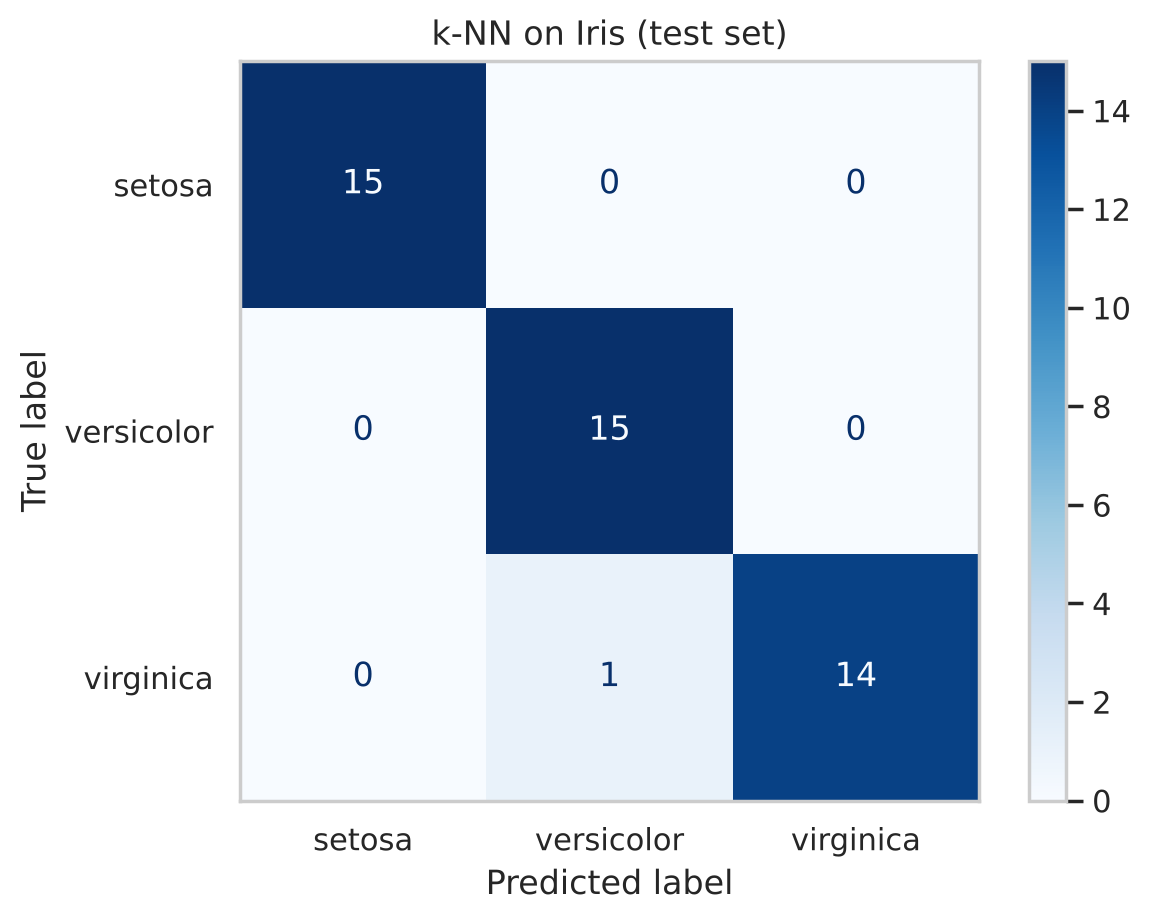

In [10]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

print(f"k-NN accuracy: {accuracy_score(y_test, y_pred):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.grid(False)
plt.title("k-NN on Iris (test set)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

همان‌طور که از نمودار اکتشافی انتظار داشتیم، *setosa* بدون خطا تشخیص داده شده و اشتباه‌های احتمالی بین *versicolor* و *virginica* است. مدل ما بسیار بهتر از مدل پایهٔ ۳۳٪ عمل می‌کند.

### ۶.۸ پیش‌بینی برای یک گل جدید

فرض کنید گلی با این اندازه‌ها پیدا کرده‌ایم. مدل آموزش‌دیده گونهٔ آن را پیش‌بینی می‌کند:

</div>

In [11]:
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=iris.feature_names)
print("Predicted species:", knn.predict(new_flower)[0])
probs = knn.predict_proba(new_flower)[0]
for species, p in zip(knn.classes_, probs):
    print(f"  P({species}) = {p:.2f}")

Predicted species: virginica
  P(setosa) = 0.00
  P(versicolor) = 0.40
  P(virginica) = 0.60


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. چرا دادهٔ آزمون جداگانه لازم است؟ نگاهی به بیش‌برازش

مدل k-NN را با $k=1$ امتحان می‌کنیم. در این حالت مدل هر نمونهٔ آموزشی را دقیقاً «حفظ» می‌کند، چون نزدیک‌ترین همسایهٔ هر نقطه خودش است.

</div>

In [12]:
for k in [1, 5, 15, 50]:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k={k:>2}  train accuracy={model.score(X_train, y_train):.3f}  "
          f"test accuracy={model.score(X_test, y_test):.3f}")

k= 1  train accuracy=1.000  test accuracy=0.933
k= 5  train accuracy=0.971  test accuracy=0.978


k=15  train accuracy=0.981  test accuracy=0.956
k=50  train accuracy=0.895  test accuracy=0.889


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با $k=1$ دقت روی دادهٔ آموزش ۱۰۰٪ است، ولی این عدد گمراه‌کننده است؛ مدل فقط داده را حفظ کرده است. معیار واقعی، دقت روی دادهٔ **آزمون** است.

- اگر مدل بیش از حد پیچیده باشد و جزئیات و نویز دادهٔ آموزش را حفظ کند، دچار **بیش‌برازش (Overfitting)** می‌شود.
- اگر بیش از حد ساده باشد (مثل $k=50$ که تقریباً یک‌سوم کل دادهٔ آموزش را میانگین می‌گیرد)، دچار **کم‌برازش (Underfitting)** می‌شود.

پیدا کردن تعادل بین این دو، یکی از مهم‌ترین موضوع‌های کل این دوره است و در جلسهٔ ۴ مفصل به آن می‌پردازیم.

## جمع‌بندی

- یادگیری ماشین یعنی یادگیری قانون از روی مثال‌ها، به‌جای نوشتن دستی آن.
- در یادگیری نظارت‌شده، برچسب درست را داریم: رگرسیون برای خروجی عددی و طبقه‌بندی برای خروجی دسته‌ای.
- جریان کار استاندارد: تعریف مسئله → داده → EDA → پیش‌پردازش → تقسیم → آموزش → ارزیابی → بهبود.
- همیشه یک **مدل پایه** بسازید و مدل را فقط روی **دادهٔ آزمون** ارزیابی کنید.
- همهٔ مدل‌های scikit-learn رابط `fit` / `predict` / `score` دارند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. داده را با `test_size=0.2` و `random_state` متفاوت تقسیم کنید. دقت مدل چقدر تغییر می‌کند؟ چه نتیجه‌ای می‌گیرید؟

۲. فقط از دو ویژگی گلبرگ (`petal length` و `petal width`) استفاده کنید. دقت بهتر شد یا بدتر؟ چرا؟

۳. به‌جای k-NN از `DecisionTreeClassifier` (از `sklearn.tree`) استفاده کنید. تنها تغییر لازم در کد کدام خط است؟

۴. مجموعه‌دادهٔ `load_wine` را بارگذاری کنید و همین جریان کار را از ابتدا تا انتها روی آن اجرا کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** داده را با `test_size=0.2` و `random_state` متفاوت تقسیم کنید. دقت مدل چقدر تغییر می‌کند؟ چه نتیجه‌ای می‌گیرید؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** فقط از دو ویژگی گلبرگ (`petal length` و `petal width`) استفاده کنید. دقت بهتر شد یا بدتر؟ چرا؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** به‌جای k-NN از `DecisionTreeClassifier` (از `sklearn.tree`) استفاده کنید. تنها تغییر لازم در کد کدام خط است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** مجموعه‌دادهٔ `load_wine` را بارگذاری کنید و همین جریان کار را از ابتدا تا انتها روی آن اجرا کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
